# Functions

A **function** $f: \mathbb{R} \to \mathbb{R}$ assigns to each input $x$ exactly one output $y = f(x)$.
The **graph** of $f$ is the set of points $(x, f(x))$ in the Cartesian plane.

Key vocabulary: **domain** (allowed $x$), **codomain / range** (resulting $y$), **zeros / roots** ($x$ where $f(x)=0$).


## Linear Function

$$f(x) = mx + b$$

| Parameter | Role |
|-----------|------|
| $m$ | **slope** — rise over run, $\Delta y / \Delta x$ |
| $b$ | **y-intercept** — value at $x = 0$ |

The graph is always a straight line. $m > 0$ → increasing, $m < 0$ → decreasing, $m = 0$ → constant.


In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot_linear(m, b):
    x = np.linspace(-5, 5, 300)
    y = m * x + b
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x, y, lw=2, label=f'$f(x) = {m:.1f}x {b:+.1f}$')
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    if m != 0:
        root = -b / m
        ax.plot(root, 0, 'ro', ms=7, label=f'root $x = {root:.2f}$')
    ax.set(xlim=(-5, 5), ylim=(-10, 10), xlabel='x', ylabel='f(x)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_title(f'Linear: $f(x) = {m:.1f}x {b:+.1f}$')
    plt.tight_layout()
    plt.show()

w_m = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='m (slope)')
w_b = widgets.FloatSlider(value=0, min=-5, max=5, step=0.1, description='b (intercept)')
widgets.interactive_output(plot_linear, {'m': w_m, 'b': w_b})
display(widgets.VBox([w_m, w_b]))
display(widgets.interactive_output(plot_linear, {'m': w_m, 'b': w_b}))


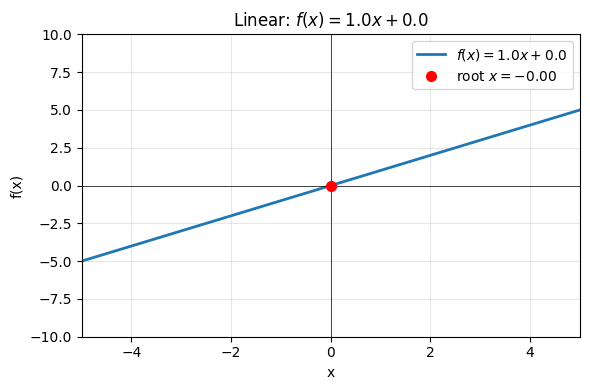

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_linear(m=w_m.value, b=w_b.value)

## Quadratic Function

$$f(x) = ax^2 + bx + c$$

| Parameter | Role |
|-----------|------|
| $a$ | opens **up** ($a>0$) or **down** ($a<0$); controls width |
| $b, c$ | shift the parabola horizontally and vertically |

**Vertex** at $x_v = -\frac{b}{2a}$, $\;y_v = f(x_v)$. &ensp; **Discriminant** $\Delta = b^2 - 4ac$ determines the number of real roots (2, 1, or 0).


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_quadratic(a, b, c):
    x = np.linspace(-5, 5, 400)
    y = a * x**2 + b * x + c
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x, y, lw=2)
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    if a != 0:
        xv = -b / (2 * a)
        yv = a * xv**2 + b * xv + c
        ax.plot(xv, yv, 'rs', ms=8, label=f'vertex ({xv:.2f}, {yv:.2f})')
        disc = b**2 - 4 * a * c
        if disc >= 0:
            r1 = (-b - np.sqrt(disc)) / (2 * a)
            r2 = (-b + np.sqrt(disc)) / (2 * a)
            ax.plot([r1, r2], [0, 0], 'go', ms=7, label='roots')
    ax.set(xlim=(-5, 5), ylim=(-10, 10), xlabel='x', ylabel='f(x)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_title(f'$f(x) = {a:.1f}x^2 {b:+.1f}x {c:+.1f}$')
    plt.tight_layout(); plt.show()

wa = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='a')
wb = widgets.FloatSlider(value=0, min=-5, max=5, step=0.1, description='b')
wc = widgets.FloatSlider(value=0, min=-5, max=5, step=0.1, description='c')
ui = widgets.VBox([wa, wb, wc])
out = widgets.interactive_output(plot_quadratic, {'a': wa, 'b': wb, 'c': wc})
display(ui, out)


## Exponential Function

$$f(x) = a \, e^{bx} + c$$

| Parameter | Role |
|-----------|------|
| $a$ | amplitude / reflection ($a < 0$ flips) |
| $b$ | growth rate ($b > 0$ → growth, $b < 0$ → decay) |
| $c$ | vertical shift (horizontal asymptote $y = c$) |

Exponentials model **unbounded growth or decay**: populations, radioactive decay, compound interest.  
Key property: $\frac{d}{dx} e^{x} = e^{x}$ — the function equals its own derivative.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_exp(a, b, c):
    x = np.linspace(-5, 5, 400)
    y = a * np.exp(b * x) + c
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x, y, lw=2, label=f'$f(x) = {a:.1f} e^{{{b:.1f}x}} {c:+.1f}$')
    ax.axhline(c, color='gray', ls='--', lw=1, label=f'asymptote $y={c:.1f}$')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set(xlim=(-5, 5), ylim=(-10, 10), xlabel='x', ylabel='f(x)')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title('Exponential Function')
    plt.tight_layout(); plt.show()

wa = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='a')
wb = widgets.FloatSlider(value=1, min=-3, max=3, step=0.1, description='b')
wc = widgets.FloatSlider(value=0, min=-5, max=5, step=0.1, description='c')
ui = widgets.VBox([wa, wb, wc])
out = widgets.interactive_output(plot_exp, {'a': wa, 'b': wb, 'c': wc})
display(ui, out)


## Logarithmic Function

$$f(x) = a \, \ln(x + b) + c$$

The natural logarithm $\ln x = \log_e x$ is the **inverse** of $e^x$: if $y = e^x$ then $x = \ln y$.

| Parameter | Role |
|-----------|------|
| $a$ | vertical stretch / reflection |
| $b$ | horizontal shift (domain becomes $x > -b$) |
| $c$ | vertical shift |

Domain restriction: argument must be **positive**, so $x + b > 0$. The graph has a vertical asymptote at $x = -b$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_log(a, b, c):
    x = np.linspace(-b + 0.01, 10, 400)
    y = a * np.log(x + b) + c
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x, y, lw=2, label=f'$f(x) = {a:.1f}\ln(x {b:+.1f}) {c:+.1f}$')
    ax.axvline(-b, color='gray', ls='--', lw=1, label=f'asymptote $x={-b:.1f}$')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set(xlim=(-2, 10), ylim=(-6, 6), xlabel='x', ylabel='f(x)')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title('Logarithmic Function')
    plt.tight_layout(); plt.show()

wa = widgets.FloatSlider(value=1, min=-3, max=3, step=0.1, description='a')
wb = widgets.FloatSlider(value=1, min=0.1, max=5, step=0.1, description='b')
wc = widgets.FloatSlider(value=0, min=-3, max=3, step=0.1, description='c')
ui = widgets.VBox([wa, wb, wc])
out = widgets.interactive_output(plot_log, {'a': wa, 'b': wb, 'c': wc})
display(ui, out)
